In [12]:
### --- PLOTTING TOOLS --- ###

import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.axes import Axes
from matplotlib.patches import Ellipse
import numpy as np

# Plotting tools

def plot_points(centroids, ax: Axes, color='red', marker='o', size=4, label=''):
    ax.scatter(centroids[:,0], centroids[:,1], s=size, marker=marker, c=color, label=label)

def plot_evaluation_points(points, ax: Axes, color='black', marker='o'):
    ax.scatter(points[:,0], points[:,1], s=20, marker=marker, c=color)

    # Also plot visual labels (letters) for each point
    shift = 0.02
    import string
    letters = list(string.ascii_uppercase)

    for j in range(len(points)):
        x = points[j,0] + shift
        y = points[j,1] + shift
        ax.text(x, y, letters[j], horizontalalignment='left')

def plot_ellipses(
        ellipses,
        ax: Axes,
        plot_numbers=False
    ):
    for j, ellipse in enumerate(ellipses):
        ax.add_patch(ellipse)

    # Plot ellipse numbers
    if plot_numbers:
        shift = 0.02
        for j in range(len(ellipses)):
            xy = ellipses[j].get_center()
            x = xy[0] + shift
            y = xy[1] + shift
            ax.text(x, y, f'{j+1}', horizontalalignment='left')

def convert_to_ellipse_object(
        Q: np.array,
        centroid: np.array,
        color = 'red',
        alpha = 0.3,
        filled = True
    ):

    D, U = np.linalg.eigh(Q)
    # Length of axes are lambda_i^{-0.5}.
    # So total diameter is 2 / D**(1/2).
    lengths = 2 * (D ** (-0.5))
    width = lengths[0]
    height = lengths[1]
    # Angle is given by the rotation matrix U.
    # In particular, the first singular vector (which corresponds to the width)
    angle = np.rad2deg(np.arctan(U[0,1] / U[0,0]))
    if filled:
        return Ellipse(
            xy=centroid,
            width=width,
            height=height,
            angle=angle,
            color=color,
            alpha=alpha,
        )
    else:
        return Ellipse(
            xy=centroid,
            width=width,
            height=height,
            angle=angle,
            alpha=1,
            facecolor='none',
            edgecolor=color,
            linewidth=1,
            linestyle='dotted'
        )

mpl.rcParams.update(mpl.rcParamsDefault)


In [9]:
### --- DEFAULT PLOT SETTINGS --- ###

mpl.rcParams.update({
    # --- Figure ---
    "figure.figsize": (3.4, 2.4),   # good for single-column papers
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02,

    # --- Fonts ---
    "font.size": 7,
    "axes.titlesize": 6,
    "axes.labelsize": 6,
    "xtick.labelsize": 6,
    "ytick.labelsize": 6,
    "legend.fontsize": 6,

    # Use LaTeX-like serif fonts (great for papers)
    "font.family": "serif",
    # "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    # "mathtext.fontset": "dejavuserif",

    # --- Axes ---
    "axes.linewidth": 0.8,
    "axes.grid": False,
    "axes.spines.top": False,
    "axes.spines.right": False,

    # --- Ticks ---
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "xtick.minor.size": 1.5,
    "ytick.minor.size": 1.5,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,

    # --- Lines ---
    "lines.linewidth": 1.5,
    "lines.markersize": 2,

    # --- Legend ---
    "legend.frameon": False,

    # --- PDF/Vector friendliness ---
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})


In [2]:
### --- CLUSTER TOOLS --- ###

from scipy.spatial import ConvexHull

# Each of the following sampling functions are centered at origin and are based on unit ball
# In other words, no ellipses
def generate_unit_ball_points_uniform(N, d=2):
    directions = np.random.randn(N, d)
    directions /= np.linalg.norm(directions, axis=1)[:,None]
    radii = np.random.random(N) ** (1/d)
    return (directions * radii[:,None])

def generate_unit_ball_points_boundary_uniform(N, d=2):
    directions = np.random.randn(N, d)
    directions /= np.linalg.norm(directions, axis=1)[:,None]
    return directions

def generate_random_polytope(V, N, d=2):

    # Generate vertices and candidate points
    candidates = generate_unit_ball_points_uniform(N, d)
    polytope_vertices = generate_unit_ball_points_boundary_uniform(V, d)

    # Build convex hull
    convex_hull = ConvexHull(polytope_vertices)
    equations = convex_hull.equations
    A = equations[:,:-1]
    b = equations[:,-1]

    # Test candidates: a point is in if Ax + b < 0.
    in_half_plane = ((candidates @ A.T) + b) < 0
    in_conv_hull_msk = in_half_plane.all(axis=1)
    polytope_points = candidates[in_conv_hull_msk]
    return polytope_points

def matrix_sqrt(Q):
    D, U = np.linalg.eigh(Q)
    return (U * (np.abs(D) ** 0.5)) @ U.T


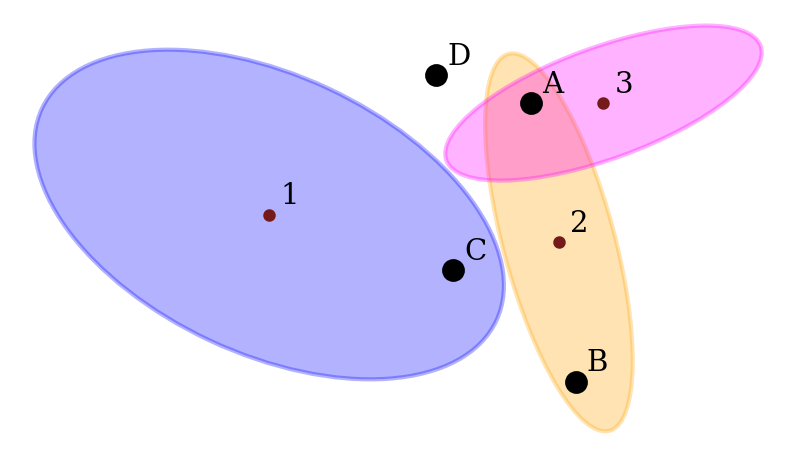

In [11]:
### --- FIGURE 1: Inference description --- ###

# Centroids and trust ellipses
centroids = np.array([
    [0.4, 0.6], # 1
    [0.92, 0.55], # 2
    [1.0, 0.8]  # 3
])
centroid_color = "#751A1A"
ellipse_colors = ['blue', 'orange', 'magenta']
trust_ellipses = [
    Ellipse(centroids[0], width=0.9, height=0.5, angle=-25,  alpha=0.3, color=ellipse_colors[0]),
    Ellipse(centroids[1], width=0.2, height=0.7, angle=15, alpha=0.3, color=ellipse_colors[1]),
    Ellipse(centroids[2], width=0.6, height=0.2, angle=20, alpha=0.3, color=ellipse_colors[2]),
]

# Example evaluation points
eval_points = np.array([
    [0.87, 0.8], # A
    [0.95, 0.3], # B
    [0.73, 0.5], # C
    [0.7, 0.85], # D
])
eval_color = 'black'

# Setting up first figure
fig1, ax1 = plt.subplots()
ax1.set_aspect('equal')
ax1.axis('off')

# Plot centroids and trust regions
plot_ellipses(trust_ellipses, ax1, plot_numbers=True)
plot_points(centroids, ax1, centroid_color, 'o')

# Plot evaluation points
plot_evaluation_points(eval_points, ax1, eval_color, 'o')
fig1.savefig('figs/inference_vis.png')

plt.show()

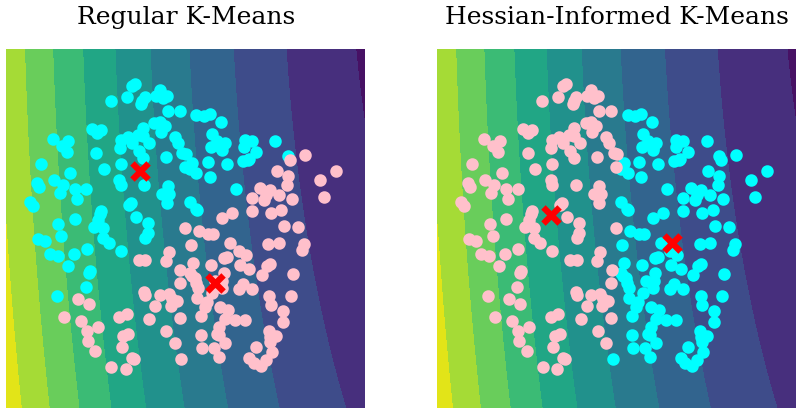

In [12]:
### --- FIGURE 2: Two-means clustering description --- ###
from src.problems.rosenbrock import rosenbrock, rosenbrock_grad, rosenbrock_hess

# Generate points in a cluster (convex region)
np.random.seed(6)
polytope_points = generate_random_polytope(8, 300)
# polytope_points = generate_unit_ball_points_uniform(250, d=2)
centroid = np.mean(polytope_points, axis=0)
centered_points = polytope_points - centroid

# Setting up second figure
fig2, ax2 = plt.subplots(1, 2)

# Underlying function for contours
s = 2
t = 2
def f(x, y):
    return 10 * (x-s) ** 2 + (y-t) ** 2
def grad_f(x, y):
    return np.column_stack((20 * (x-s), 2 * (y-t)))
def hess_f(x, y): # just takes a single point
    return np.array([
        [20, 0],
        [0, 2]
    ])
# def f(x, y):
#     return rosenbrock(np.column_stack((x,y)))
# def grad_f(x, y):
#     return rosenbrock_grad(np.column_stack((x,y)))
# def hess_f(x, y): # just takes a single point
#     return rosenbrock_hess(np.column_stack((x,y)))
x = np.linspace(-1.1, 1.1, 400)
X, Y = np.meshgrid(x, x)
Z = f(X, Y)

# Recluster the points

# A. K-Means (First eigenvector of covariance matrix, entire function)
_, _, V = np.linalg.svd(centered_points)
assign_msk_A = (centered_points @ V[0]) > 0
centroid_1A = np.mean(polytope_points[assign_msk_A], axis=0)
centroid_2A = np.mean(polytope_points[~assign_msk_A], axis=0)

# B. K-Means with fewer points (first evec of small covariance matrix)
# first compute error of points
f_centroid = f(centroid[0], centroid[1]).flatten()
g_centroid = grad_f(centroid[0], centroid[1]).flatten()
dx = polytope_points - centroid
linear_approx = f_centroid + dx @ g_centroid
exact = f(polytope_points[:,0], polytope_points[:,1]).flatten()
errors = np.abs(linear_approx - exact)
eps = 4
error_msk = errors < eps
# now compute covariance of the smaller matrix
centered_points_good_err = centered_points[error_msk]
_, _, V = np.linalg.svd(centered_points_good_err)
assign_msk_B = (polytope_points @ V[0]) > 0
centroid_1B = np.mean(polytope_points[assign_msk_B], axis=0)
centroid_2B = np.mean(polytope_points[~assign_msk_B], axis=0)

# C. Use Hessian
h_centroid = hess_f(centroid[0], centroid[1])
sqrt_h_centroid = matrix_sqrt(h_centroid).reshape(2,2)
_, _, V = np.linalg.svd(centered_points @ sqrt_h_centroid)
assign_msk_C = (polytope_points @ V[0]) > 0
centroid_1C = np.mean(polytope_points[assign_msk_C], axis=0)
centroid_2C = np.mean(polytope_points[~assign_msk_C], axis=0)

# Plot the contours for each plot
for ax in ax2:
    ax.set_aspect('equal', adjustable='box')
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
    ax.contourf(X, Y, Z, levels=10, cmap='viridis')


# Plot the points and other settings
c1 = 'cyan'
c2 = 'pink'

# Plot A
plot_points(polytope_points[assign_msk_A],  ax2[0], c1, 'o')
plot_points(polytope_points[~assign_msk_A], ax2[0], c2, 'o')
ax2[0].axis('off')
ax2[0].set_title('Regular K-Means')
ax2[0].scatter(centroid_1A[0], centroid_1A[1], c='red', marker='x', s=15)
ax2[0].scatter(centroid_2A[0], centroid_2A[1], c='red', marker='x', s=15)
# Plot B
# plot_points(polytope_points[assign_msk_B],  ax2[1], c1, 'o')
# plot_points(polytope_points[~assign_msk_B], ax2[1], c2, 'o')
# Plot C
plot_points(polytope_points[assign_msk_C],  ax2[1], c1, 'o')
plot_points(polytope_points[~assign_msk_C], ax2[1], c2, 'o')
ax2[1].axis('off')
ax2[1].set_title('Hessian-Informed K-Means')
ax2[1].scatter(centroid_1C[0], centroid_1C[1], c='red', marker='x', s=15)
ax2[1].scatter(centroid_2C[0], centroid_2C[1], c='red', marker='x', s=15)

plt.show()
fig2.savefig('hessian_kmeans.png')


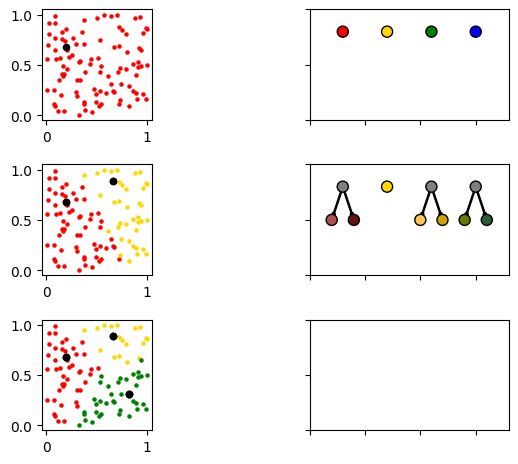

In [5]:
### --- FIGURE 3: Tree Figure --- ###

from src.adaptive_clustering import adaptive_clustering
from matplotlib.patches import Circle, Arrow

# Training data
train_data = np.random.uniform(0, 1, (100, 2))

# extremely slow (with for loop) but fine for plotting
def _assign_labels(sources, targets):
    assignments = np.zeros(len(targets))
    for j, target in enumerate(targets):
        assignments[j] = np.argmin(np.linalg.norm(sources-target, 2, axis=1))
    return assignments

def plot_level_of_algorithm(level, ax):
    output = adaptive_clustering(
        X = train_data,
        f_fn = rosenbrock,
        g_fn = rosenbrock_grad,
        TOL = 0.1,
        ERROR_METRIC='Linf-local',
        NUM_INITIAL_CLUSTERS=4,
        SEED=0,
        MAX_LEVELS=level
    )
    centers = output['centroids']
    labels = _assign_labels(centers, train_data)
    for j in range(len(centers)):
        ax.scatter(train_data[labels==j][:,0], train_data[labels==j][:,1], marker='o', s=5, c=colors[j])
        ax.scatter(centers[:,0], centers[:,1], c='black', marker='o', s=20)
    # ax.set_xlim(0,1)
    # ax.set_ylim(0,1)

colors = ['red', 'gold', 'green', 'blue',
            "#671313", "#af5252", "#FFC74D", "#CEA200",
            '#2b5d34', "#657c02", "#66b6f3", "#2203ab",]

fig, axs = plt.subplots(nrows=3, ncols=2, gridspec_kw={'width_ratios': [1, 2]})
fig.tight_layout()

# Original clusters
plot_level_of_algorithm(1, axs[0,0])

# Make the corresponding tree
circles = [
    Circle((0.3,0.8), 0.05, facecolor=colors[0], edgecolor='black'),
    Circle((0.7,0.8), 0.05, facecolor=colors[1], edgecolor='black'),
    Circle((1.1,0.8), 0.05, facecolor=colors[2], edgecolor='black'),
    Circle((1.5,0.8), 0.05, facecolor=colors[3], edgecolor='black'),
]
for circle in circles:
    axs[0,1].add_patch(circle)

# Plot second level
plot_level_of_algorithm(2, axs[1,0])

# Make the tree for the second plot
lines = [
    Arrow(0.3, 0.8, -0.1, -0.3, width=0.05, color='black'),
    Arrow(0.3, 0.8,  0.1, -0.3, width=0.05, color='black'),
    Arrow(1.1, 0.8, -0.1, -0.3, width=0.05, color='black'),
    Arrow(1.1, 0.8,  0.1, -0.3, width=0.05, color='black'),
    Arrow(1.5, 0.8, -0.1, -0.3, width=0.05, color='black'),
    Arrow(1.5, 0.8,  0.1, -0.3, width=0.05, color='black'),
]
circles = [
    Circle((0.3,0.8), 0.05, facecolor='grey', edgecolor='black'),
    Circle((0.7,0.8), 0.05, facecolor=colors[1], edgecolor='black'),
    Circle((1.1,0.8), 0.05, facecolor='grey', edgecolor='black'),
    Circle((1.5,0.8), 0.05, facecolor='grey', edgecolor='black'),
    Circle((0.2,0.5), 0.05, facecolor=colors[5], edgecolor='black'),
    Circle((0.4,0.5), 0.05, facecolor=colors[4], edgecolor='black'),
    Circle((1.0,0.5), 0.05, facecolor=colors[6], edgecolor='black'),
    Circle((1.2,0.5), 0.05, facecolor=colors[7], edgecolor='black'),
    Circle((1.4,0.5), 0.05, facecolor=colors[9], edgecolor='black'),
    Circle((1.6,0.5), 0.05, facecolor=colors[8], edgecolor='black'),
]
for line in lines:
    axs[1,1].add_patch(line)
for circle in circles:
    axs[1,1].add_patch(circle)


plot_level_of_algorithm(3, axs[2,0])


for i in range(len(axs)):
    for j in range(len(axs[0])):
        if j == 1 and i <= 2:
            axs[i,1].set_yticklabels([])
            axs[i,1].set_xticklabels([])
            axs[i,1].set_xlim(0,1.8)
            axs[i,1].set_ylim(0,1)
        axs[i,j].set_aspect('equal', adjustable='box')

plt.show()



/var/folders/pc/_rlr7wmn33s7hb9l9kpgsj3w0000gn/T/ipykernel_96224/1840166099.py:12: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(centroids[:,0], centroids[:,1], s=size, marker=marker, c=color, label=label)


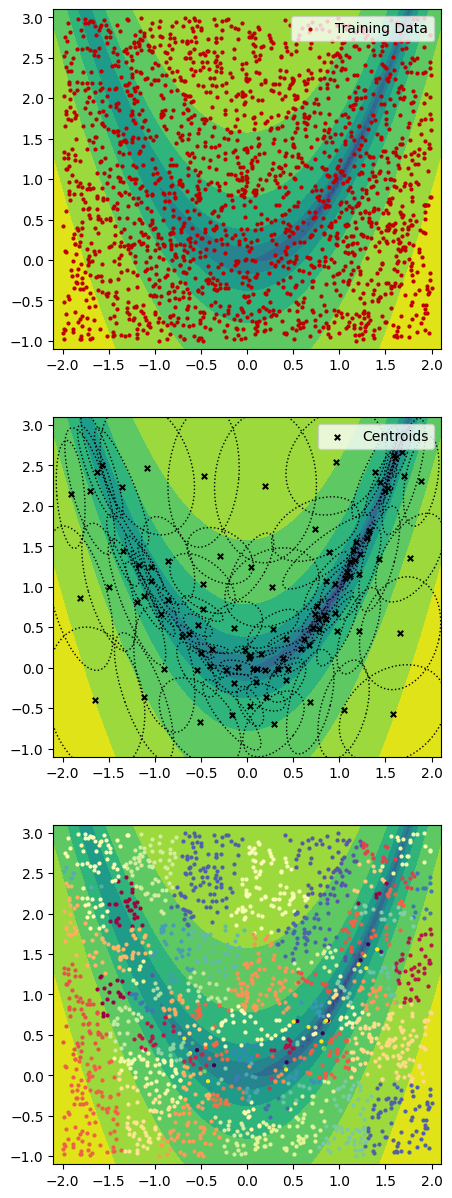

In [ ]:
### --- FIGURE 4: Entire description of algorithm --- ###
'''
Underlying function: Rosenbrock 2D
Fig (a): input points
Fig (b): final points (centroids) after running algorithm
Fig (c): colored leaf clusters (input points but reclustered)
Fig (d): tree
'''

from src.surrogate import HATANNSurrogate
from src.problems.rosenbrock import rosenbrock, rosenbrock_grad

# Training data
d = 2
N = 2000
X_train = np.column_stack((np.random.uniform(-2, 2, N), np.random.uniform(-1, 3, N)))

# Adaptive clustering parameters
N_init_clusters = 10
tol = 0.2

# Trained surrogate
surrogate = HATANNSurrogate(version='v2')
surrogate.train(
    X_train,
    f_fn = rosenbrock,
    g_fn = rosenbrock_grad,
    save_model = False,
    TOL = tol,
    ERROR_METRIC = 'Linf-local',
    NUM_INITIAL_CLUSTERS = N_init_clusters,
    MIN_PTS_PER_CLUSTER = 10,
    MAX_CLUSTERS_EST = 10000,
    SEED = 0,
    USE_HESSIAN_INFORMED_SPLIT = True,
    IGNORE_GRADIENT = False
)

# plots
fig, ax = plt.subplots(3, 1, figsize=(5, 15))

# contour data
x = np.linspace(-2.1, 2.1, 400)
y = np.linspace(-1.1, 3.1)
X, Y = np.meshgrid(x, y)
XY = np.column_stack([X.ravel(), Y.ravel()])
Z_flat = rosenbrock(XY, a=100)
Z = Z_flat.reshape(X.shape)

# Fig (a): training data
ax[0].contourf(X, Y, np.log10(Z), levels=10, cmap='viridis')
plot_points(X_train, ax[0], color="#BD0000", marker='o', label='Training Data')
xlims = ax[0].get_xlim()
ylims = ax[0].get_ylim()
ax[0].legend(loc='upper right')

# Fig (b): centroids after running alg
p = 1
centroids = surrogate.get_source_centroids()
TRs = surrogate.get_trust_regions()
ellipses = []
for j, TR in enumerate(TRs):
    ellipses.append(convert_to_ellipse_object(TR, centroids[j], "#000000", filled=False))
ax[p].contourf(X, Y, np.log10(Z), levels=10, cmap='viridis')
plot_points(centroids, ax[1], color="#000000", marker='x', size=15, label='Centroids')
plot_ellipses(ellipses, ax[1], False)
ax[p].set_xlim(xlims)
ax[p].set_ylim(ylims)
ax[p].legend(loc='upper right')

# Fig (c): colored input points (but reclustered)
p = 2
ax[p].contourf(X, Y, np.log10(Z), levels=10, cmap='viridis')
labels = _assign_labels(centroids, X_train)
cmap = plt.get_cmap('Spectral')
plot_colors = [cmap(x) for x in np.random.rand(len(centroids))]
for j in range(len(centroids)):
    plot_points(X_train[labels==j], ax[p], np.array(plot_colors[j % len(plot_colors)]))
xlims = ax[0].get_xlim()
ylims = ax[0].get_ylim()
ax[p].set_xlim(xlims)
ax[p].set_ylim(ylims)
# plot_points(centroids, ax[p], color="#000000", marker='x', size=10)
# plot_ellipses(ellipses, ax[p], False)


plt.show()


